# Tools - Flow : Inverting equivalent resistances
Assuming a network where the equivalent resistance on every edge is known. The goal is to retrieve the conductance on every edge.
This is can be done with the dedicated function `kn.tools.invert_Req`, as illustrated in this notebook.

*Note. Presented tool works on `networkx.Graph` objects. A `KGraph` object `kg` can be defined from a `networkx.Graph` graph `g` with `kg = kn.from_networkx(g)`.*

In [1]:
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
import scipy
import time
# import tqdm
# import functools

# import skimage
# import geone as gn

In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
# import pyvista as pv

# # Choose backend for pyvista with jupyter
# # ---------------------------------------
# pv.set_jupyter_backend('static') # static plots
# # pv.set_jupyter_backend('trame')  # 3D-interactive plots

# # Notes:
# # -> ignored if run in a standard python shell
# # -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.6


## Notations
Consider a graph $G=(V, E)$ and note the vertices $V=\{1, \ldots, n\}$ and note an edge $ij$ if $i\sim j$ is an edge (i.e. $\{i, j\} \in E$).

Consider:
- $T_{ij}$ : the conductance on the edge $ij$
- $L$ : the Laplacian matrix with conductance as edge weight
- $R^{eq}_{ij}$ : the equivalent resistance on the edge $ij$
- $p^{(\star, ij)}$ : the vector of node potential, s.t. $L\cdot p^{(\star, ij)} = \delta_i - \delta_j$, i.e. the solution of the flow equation $Lp=q$ where $q$ is the source term (entering fluxes at nodes), here: flux of 1 entering at node $i$ and exiting at node $j$

## 1. Jacobian of equivalent resistances

With edge indices $ij$ and $kl$, we have 
- $\displaystyle \frac{\partial R^{(eq)}_{ij}}{\partial T_{kl}} = - \left(p^{(\star, ij)}_k - p^{(\star, ij)}_l\right)^2$ (analytical result)

One can also compute the Jacobian numerically as 
- $\displaystyle \frac{\partial R^{(eq)}_{ij}}{\partial T_{kl}} \approx \frac{R^{(eq)}_{ij}(T + h\cdot\mathbf{1_{kl}}) - R^{(eq)}_{ij}(T - h\cdot\mathbf{1_{kl}})}{2 h}$


### Example on a small percolation network / percolation cluster
A binary medium is generatated in a grid, where each cell is independently activated according to a site activation probability. 
The graph of the network is then built, where the nodes are the activated cells and the edges link the adjacent activated cells in the grid.


In [5]:
mx, my = 6, 8 # size of the grid
p = .9       # site activation probability
seed = 32     # random seed for reproducibility

# Get list of graphs corresponding to the connected components
g_list = kn.misc.random_cluster_in_grid_2d(
        mx, my, p, 
        sx=1.0, 
        sy=1.0, 
        seed=seed, 
        extract_connected_components=True,
        renumbering_nodes=True,
        return_array=False)

# Get the largest connected component
g = g_list[0]

# Set string for some node labels
new_labels = {n: i for i, n in enumerate(g.nodes())}
new_labels[1] = 'a'
new_labels[2] = 'b'
new_labels[5] = 'x'

g = nx.relabel_nodes(g, new_labels, copy=False)

In [6]:
# Options for plot of 2D graph
options = {
    'node_size'   : 250,         # node size
    'linewidths'  : 1,          # node border width      
    'edgecolors'  : 'gray',      # node border color
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True,        # aspect ratio equal ?
    'font_size'   : 10,           # font size for node labels
}

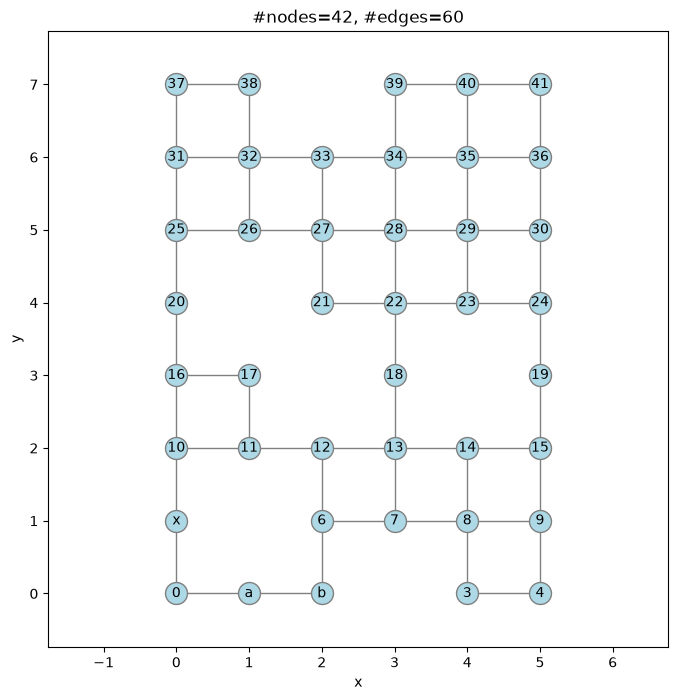

In [7]:
# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.title(f'#nodes={g.number_of_nodes()}, #edges={g.number_of_edges()}')
plt.show()

In [8]:
n_nodes = g.number_of_nodes()
n_edges = g.number_of_edges()

### Set reference (true) conductances on the edges
Set ''true conductances'' $T^{true}_{ij}$ for all edges $ij$, with $log(T) \sim \mathcal{N}(m, s^2)$.

In [9]:
# Set true conductances on the edges
# ----------------------------------
seed = 59
np.random.seed(seed)
m = 0.0
s = 1.0
T_true_arr = np.exp(scipy.stats.norm(loc=m, scale=s).rvs(n_edges)) # random values in log-normal distribution
T_true = {e: t for e, t in zip(g.edges(), T_true_arr)}

nx.set_edge_attributes(g, T_true, 'T_true')

### Compute the eigen values and eigen vectors of the Laplacian matrix

In [10]:
# Compute (first) eigen values and eigen vectors of the Laplacian matrix,
# used further for (approximation) of the pseudo-inverse of the Laplacian matrix
k = None # maximum number of eigen values and eigen vectors to compute (None: all)

if k is None:
    print('Compute all eigen values and eigen vectors of the Laplacian matrix')
else:
    print(f'Compute the first {k} (at max.) eigen values and eigen vectors of the Laplacian matrix')

t1 = time.time()
lap_T_true_eigval, lap_T_true_eigvec = kn.tools.laplacian_eigs(g, edge_weight='T_true', k=k)
t2 = time.time()

print(f'Elapsed time: {t2-t1:.2f} sec')

Compute all eigen values and eigen vectors of the Laplacian matrix
Elapsed time: 0.00 sec


### Compute reference (true) equivalent resistance on every edge
Compute $R^{eq, true}_{ij}$, on all edges $ij$.

In [11]:
# Compute equivalent conductance on every edge
arr = kn.tools.equivalent_conductance(g, g.edges(), eigval=lap_T_true_eigval, eigvec=lap_T_true_eigvec) # using pre-computed eigen values and eigen vectors

Req_true_arr = 1 / arr # equivalent resistances
Req_true = {e: t for e, t in zip(g.edges(), Req_true_arr)}

nx.set_edge_attributes(g, Req_true, 'Req_true')

### Jacobian of equivalent resistances - analytical
- $\displaystyle \frac{\partial R^{(eq)}_{ij}}{\partial T_{kl}} = - \left(p^{(\star, ij)}_k - p^{(\star, ij)}_l\right)^2$

In [12]:
# Compute Jacobian of equivalent resistances Req_true - analytically
# ------------------------------------------------------------------
# For edges e and f: 
#   (d Req_true(e))/(d T(f)) = - (pe[f[0]] - pe[f[1]])**2
# where T is the conductance (T_true), and pe is the potential such that 
#   L  pe = qe
# with 
#   - L : Lapacian
#   - qe : source term with qe[e[0]] = 1 qe[e[1]]= -1, qe[u] = 0 for other nodes u
#
# Storage
# -------
# J_Req_true: dictionary with 
#   - key   : edge e
#   - value : gradient of R_eq_true(e), dictionary with
#       - key   : edge f
#       - value : (d R_eq_true(e))/(d T(f))
#
# J_Req_true_arr: 2d array of shape (n_edges, n_edges)


# # ----- using dictionary -----
# J_Req_true = {}

# for e in g.edges():
#     q_nodes_dict = {u: 0.0 for u in g.nodes()}
#     q_nodes_dict[e[0]] = 1.0
#     q_nodes_dict[e[1]] = -1.0
#     p_nodes_dict = kn.tools.solve_flow_without_bc(g, q_nodes_dict=q_nodes_dict, eigval=lap_T_true_eigval, eigvec=lap_T_true_eigvec)

#     J_Req_true[e] = {f: - (p_nodes_dict[f[0]] - p_nodes_dict[f[1]])**2 for f in g.edges()}

# J_Req_true_arr = np.asarray([list(J_Req_true[e].values()) for e in g.edges()])
# # -----

# ----- directly in array form (1) -----
J_Req_true_arr = []

for i, e in enumerate(g.edges()):
    q_nodes_dict = {u: 0.0 for u in g.nodes()}
    q_nodes_dict[e[0]] = 1.0
    q_nodes_dict[e[1]] = -1.0
    p_nodes_dict = kn.tools.solve_flow_without_bc(g, q_nodes_dict=q_nodes_dict, eigval=lap_T_true_eigval, eigvec=lap_T_true_eigvec)

    J_Req_true_arr.append([- (p_nodes_dict[f[0]] - p_nodes_dict[f[1]])**2 for f in g.edges()])

J_Req_true_arr = np.asarray(J_Req_true_arr)
# -----

# # ----- directly in array form (2) -----
# node_label2index = {u:i for i, u in enumerate(g.nodes())} # dictionary to convert node label to node index
# # node_label2index = kn.utils.get_node_label2index_dict(g) # equiv.

# J_Req_true_arr2 = np.zeros((n_edges, n_edges))

# for i, e in enumerate(g.edges()):
#     q = np.zeros(n_nodes)
#     i0, i1 = node_label2index[e[0]], node_label2index[e[1]]
#     q[i0] = 1.0
#     q[i1] = -1.0
#     p = (lap_T_true_eigvec[:, 1:] * 1.0/lap_T_true_eigval[1:]) @ lap_T_true_eigvec[:, 1:].T @ q

#     J_Req_true_arr2[i, :] = [- (p[node_label2index[f[0]]] - p[node_label2index[f[1]]])**2 for f in g.edges()]
# # -----


### Jacobian of equivalent resistances - numerically
- $\displaystyle \frac{\partial R^{(eq)}_{ij}}{\partial T_{kl}} \approx \frac{R^{(eq)}_{ij}(T + h\cdot\mathbf{1_{kl}}) - R^{(eq)}_{ij}(T - h\cdot\mathbf{1_{kl}})}{2 h}$

with $h>0$ small.


In [13]:
# Compute Jacobian of equivalent resistances Req_true
#
# Numerical computation
# ---------------------
# For edges e and f: 
#   (d Req_true(e))/(d T(f)) estimated by ((Req_true(T + h*1_f) - Req_true(T - h*1_f))(e))/(2*h)
#
# Storage
# -------
# J_Req_true_num_arr: 2d array of shape (n_edges, nedges)

J_Req_true_num_arr = np.zeros((n_edges, n_edges))

h = 1.e-4
for j, e in enumerate(g.edges()):
    # Compute d R_eq / de (i.e. j-th column of Jacobian)
    d = nx.get_edge_attributes(g, 'T_true')

    d[e] = d[e] + h
    nx.set_edge_attributes(g, d, 'T_tmp')
    a_arr = kn.tools.equivalent_conductance(g, g.edges(), edge_weight='T_tmp')
    Req_a_arr = 1 / a_arr # equivalent resistances

    d[e] = d[e] - 2*h
    nx.set_edge_attributes(g, d, 'T_tmp')
    b_arr = kn.tools.equivalent_conductance(g, g.edges(), edge_weight='T_tmp')
    Req_b_arr = 1 / b_arr # equivalent resistances

    J_Req_true_num_arr[:, j] = (Req_a_arr - Req_b_arr) / (2*h) 


In [14]:
# # Compute Jacobian of equivalent resistances Req_true
# #
# # Numerical computation
# # ---------------------
# # For edges e and f: 
# #   (d Req_true(e))/(d T(f)) estimated by ((Req_true(T + h*1_f) - Req_true(T))(e))/dT
# #
# # Storage
# # -------
# # J_Req_true_num_arr: 2d array of shape (n_edges, nedges)

# J_Req_true_num_arr = np.zeros((n_edges, n_edges))

# h = 1.e-4
# for j, e in enumerate(g.edges()):
#     # Compute d R_eq / de (i.e. j-th column of Jacobian)
#     d = nx.get_edge_attributes(g, 'T_true')

#     d[e] = d[e] + h
#     nx.set_edge_attributes(g, d, 'T_tmp')
#     a_arr = kn.tools.equivalent_conductance(g, g.edges(), edge_weight='T_tmp')
#     Req_a_arr = 1 / a_arr # equivalent resistances

#     Req_b_arr = np.asarray(list(Req_true.values()))

#     J_Req_true_num_arr[:, j] = (Req_a_arr - Req_b_arr) / h 


### Comparison of analytical Jacobian and numerical Jacobian

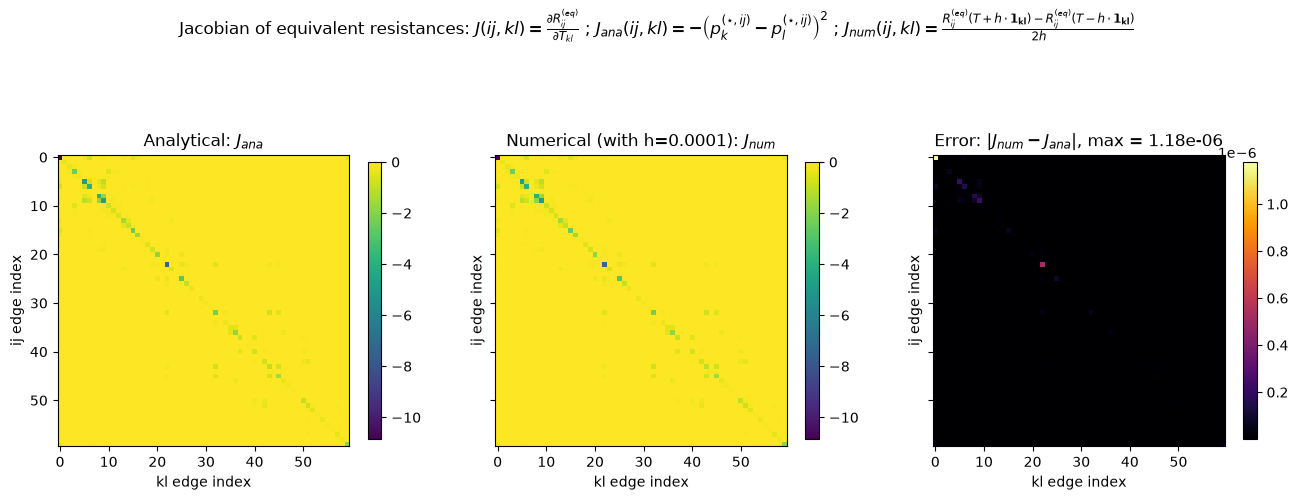

In [15]:
J_err = np.abs(J_Req_true_num_arr - J_Req_true_arr)
J_err_max = np.max(J_err)

colorbar_shrink = 0.6

plt.subplots(1, 3, figsize=(16, 6), sharex=True, sharey=True)

plt.subplot(1, 3, 1)
plt.imshow(J_Req_true_arr, cmap='viridis')
plt.colorbar(shrink=colorbar_shrink)
# plt.gca().xaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8, rotation=60)
# plt.gca().yaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8)
plt.xlabel('kl edge index')
plt.ylabel('ij edge index')
plt.title(r'Analytical: $J_{ana}$')

plt.subplot(1, 3, 2)
plt.imshow(J_Req_true_num_arr, cmap='viridis')
plt.colorbar(shrink=colorbar_shrink)
# plt.gca().xaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8, rotation=60)
# plt.gca().yaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8)
plt.xlabel('kl edge index')
plt.ylabel('ij edge index')
plt.title(f'Numerical (with h={h}):' + r' $J_{num}$')

plt.subplot(1, 3, 3)
plt.imshow(J_err, cmap='inferno')
plt.colorbar(shrink=colorbar_shrink)
# plt.gca().xaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8, rotation=60)
# plt.gca().yaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8)
plt.xlabel('kl edge index')
plt.ylabel('ij edge index')
plt.title(r'Error: $\vert J_{num} - J_{ana}\vert$' + f', max = {J_err_max:.2e}')

#plt.suptitle(r'Jacobian of equivalent resistances $\frac{\partial R^{(eq)}_{ij}}{\partial T_{kl}}$', fontsize=12)
# plt.suptitle(r'Jacobian of equivalent resistances: $\partial R^{(eq)}_{ij} / \partial T_{kl}$', fontsize=12)
plt.suptitle(r'Jacobian of equivalent resistances: $J(ij, kl) = \frac{\partial R^{(eq)}_{ij}}{\partial T_{kl}}$' + ' ; ' + #'\n' + 
             r'$J_{ana}(ij, kl)= - \left(p^{(\star, ij)}_k - p^{(\star, ij)}_l\right)^2$' + ' ; ' + #'\n' + 
             r'$J_{num}(ij, kl)= \frac{R^{(eq)}_{ij}(T + h\cdot\mathbf{1_{kl}}) - R^{(eq)}_{ij}(T - h\cdot\mathbf{1_{kl}})}{2 h}$',
             fontsize=12)
plt.show()



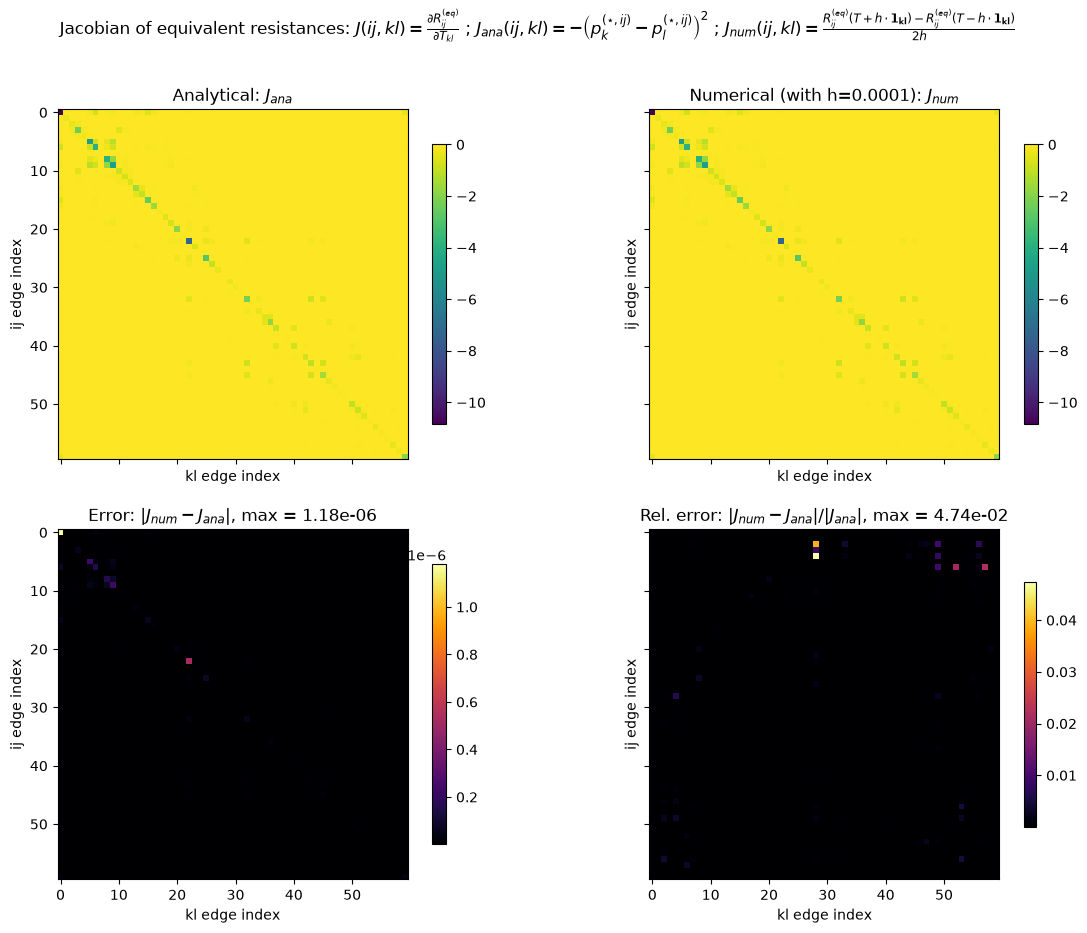

In [16]:
J_err = np.abs(J_Req_true_num_arr - J_Req_true_arr)
J_err_max = np.max(J_err)
#J_err_rel = J_err / np.abs(J_Req_true_arr)
J_err_rel = J_err / (np.abs(J_Req_true_arr) + 1.e-10)
J_err_rel_max = np.max(J_err_rel)

colorbar_shrink = 0.8

plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)


plt.subplot(2, 2, 1)
plt.imshow(J_Req_true_arr, cmap='viridis')
plt.colorbar(shrink=colorbar_shrink)
# plt.gca().xaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8, rotation=60)
# plt.gca().yaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8)
plt.xlabel('kl edge index')
plt.ylabel('ij edge index')
plt.title(r'Analytical: $J_{ana}$')

plt.subplot(2, 2, 2)
plt.imshow(J_Req_true_num_arr, cmap='viridis')
plt.colorbar(shrink=colorbar_shrink)
# plt.gca().xaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8, rotation=60)
# plt.gca().yaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8)
plt.xlabel('kl edge index')
plt.ylabel('ij edge index')
plt.title(f'Numerical (with h={h}):' + r' $J_{num}$')

plt.subplot(2, 2, 3)
plt.imshow(J_err, cmap='inferno')
plt.colorbar(shrink=colorbar_shrink)
# plt.gca().xaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8, rotation=60)
# plt.gca().yaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8)
plt.xlabel('kl edge index')
plt.ylabel('ij edge index')
plt.title(r'Error: $\vert J_{num} - J_{ana}\vert$' + f', max = {J_err_max:.2e}')

plt.subplot(2, 2, 4)
plt.imshow(J_err_rel, cmap='inferno')
plt.colorbar(shrink=0.7)
# plt.gca().xaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8, rotation=60)
# plt.gca().yaxis.set_ticks(ticks=np.arange(n_edges), labels=g.edges(), fontsize=8)
plt.xlabel('kl edge index')
plt.ylabel('ij edge index')
plt.title(r'Rel. error: $\vert J_{num} - J_{ana}\vert / \vert J_{ana}\vert$' + f', max = {J_err_rel_max:.2e}')

#plt.suptitle(r'Jacobian of equivalent resistances $\frac{\partial R^{(eq)}_{ij}}{\partial T_{kl}}$', fontsize=12)
# plt.suptitle(r'Jacobian of equivalent resistances: $\partial R^{(eq)}_{ij} / \partial T_{kl}$', fontsize=12)
plt.suptitle(r'Jacobian of equivalent resistances: $J(ij, kl) = \frac{\partial R^{(eq)}_{ij}}{\partial T_{kl}}$' + ' ; ' + #'\n' + 
             r'$J_{ana}(ij, kl)= - \left(p^{(\star, ij)}_k - p^{(\star, ij)}_l\right)^2$' + ' ; ' + #'\n' + 
             r'$J_{num}(ij, kl)= \frac{R^{(eq)}_{ij}(T + h\cdot\mathbf{1_{kl}}) - R^{(eq)}_{ij}(T - h\cdot\mathbf{1_{kl}})}{2 h}$',
             fontsize=12)
plt.show()



## 2. Inversion of equivalent resistances

Assume that equivalent resistances $R^{eq,\, true}_{ij}$ are known, and find the edge conductances $T_{ij}$ (considering reference conductances $T^{true}_{ij}$ unknown).

### Optimisation approach
Let $E$ be the set of edge and consider, with $m=\vert E\vert$, the non linear function 
- $R^{eq}: \mathbb{R}^m \longrightarrow \mathbb{R}^m, T \longmapsto R^{eq}(T) = \left(R^{eq}_{ij}(T)\right)_{ij\in E}$

The goal is to find edge conductance $T=(T_{kl})$ such that $R^{eq}(T) = R^{eq,\, true}$, or to find $T$ that minimizes the squared norm of the resiudal vector
- $r(T) = R^{eq}(T) - R^{eq,\, true}$

### Iterative scheme (Gauss-Newton)
The solution can be evaluated iteratively by linearizing the function $R^{eq}$. Given the previous estimate $T^{(s)}$ (at step $s$),
$R^{eq}$ is linearized as
- $R^{eq}\left(T^{(s)} + \delta T\right) \approx R^{eq}\left(T^{(s)}\right) + J_{R^{eq}}\left(T^{(s)}\right)\cdot \delta T$

where $\delta T \in \mathbb{R}^m$ and $J_{R^{eq}} = \left(\partial R^{eq}_{ij}/\partial T_{kl}\right)$ is the jacobian matrix of $R^{eq}$.
The next estimate is then computed as
- $T^{(s+1)} = T^{(s)} + \delta T$

with $\delta T$ the least squares solution of the system $R^{eq}\left(T^{(s)}\right) + J_{R^{eq}}\left(T^{(s)}\right)\cdot \delta T = R^{eq,\, true}$, i.e. 
- $\left(J_{R^{eq}}\left(T^{(s)}\right)\right)^\top \cdot J_{R^{eq}}\left(T^{(s)}\right)\cdot \delta T = - \left(J_{R^{eq}}\left(T^{(s)}\right)\right)^\top \cdot r\left(T^{(s)}\right)$

### Starting point
The initial guess is set as
- $T^{(0)}_{kl} \propto \left(\frac{1}{2}(d_k + d_l)\right)^{-1} \cdot \frac{1}{R^{eq,\, given}_{kl}}$

with $d_k$ (resp. $d_l$) the (unweighted) degree of node $k$ (resp. $l$). Moreover the vector $T^{(0)}$ is (re-)scaled such that $\sum_{kl\in E}T^{(0)}_{kl} R^{eq,\, given}_{kl} = n - 1$ according to the property of leverage scores.

*Note: at each iteration the estimate $T^{(s)}$ can be clipped to avoid negative values and re-scaled such that $\sum_{kl\in E}T^{(s)}_{kl} R^{eq,\, given}_{kl} = n - 1$.*

### Example on a small percolation network / percolation cluster
A binary medium is generatated in a grid, where each cell is independently activated according to a site activation probability. 
The graph of the network is then built, where the nodes are the activated cells and the edges link the adjacent activated cells in the grid.


In [17]:
mx, my = 25, 25 # size of the grid
p = 0.75        # site activation probability
seed = 3452     # random seed for reproducibility

# Get list of graphs corresponding to the connected components
g_list = kn.misc.random_cluster_in_grid_2d(
        mx, my, p, 
        sx=1.0, 
        sy=1.0, 
        seed=seed, 
        extract_connected_components=True,
        renumbering_nodes=True,
        return_array=False)

# Get the largest connected component
g = g_list[0]

In [18]:
# Options for plot of 2D graph
options = {
    'node_size'   : 5,         # node size
    'linewidths'  : 1,          # node border width      
    # 'edgecolors'  : 'gray',      # node border color
    'node_color'  : 'tab:blue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : False,        # show node labels ?
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True,        # aspect ratio equal ?
    # 'font_size'   : 6,           # font size for node labels
}

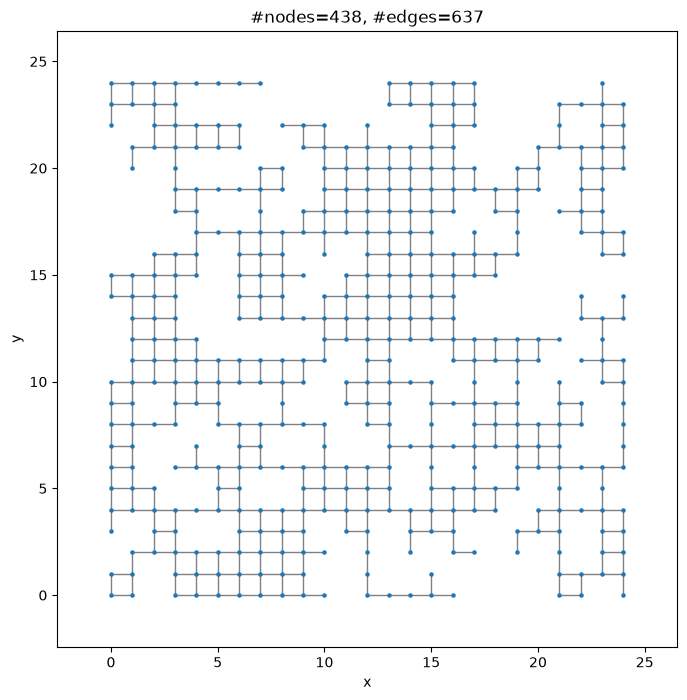

In [19]:
# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.title(f'#nodes={g.number_of_nodes()}, #edges={g.number_of_edges()}')
plt.show()

In [20]:
# Get number of nodes and number of edges
n_nodes = g.number_of_nodes()
n_edges = g.number_of_edges()

### Set reference (true) conductances on the edges
Set ''true conductances'' $T^{true}_{ij}$ for all edges $ij$, with $log(T) \sim \mathcal{N}(m, s^2)$.

In [21]:
# Set true conductances on the edges
# ----------------------------------
seed = 59
np.random.seed(seed)
m = 0.0
s = 1.0
T_true_arr = np.exp(scipy.stats.norm(loc=m, scale=s).rvs(n_edges)) # random values in log-normal distribution
T_true = {e: t for e, t in zip(g.edges(), T_true_arr)}

nx.set_edge_attributes(g, T_true, 'T_true')

### Compute the eigen values and eigen vectors of the Laplacian matrix

In [22]:
# Compute (first) eigen values and eigen vectors of the Laplacian matrix,
# used further for (approximation) of the pseudo-inverse of the Laplacian matrix
k = None # maximum number of eigen values and eigen vectors to compute (None: all)

if k is None:
    print('Compute all eigen values and eigen vectors of the Laplacian matrix')
else:
    print(f'Compute the first {k} (at max.) eigen values and eigen vectors of the Laplacian matrix')

t1 = time.time()
lap_T_true_eigval, lap_T_true_eigvec = kn.tools.laplacian_eigs(g, edge_weight='T_true', k=k)
t2 = time.time()

print(f'Elapsed time: {t2-t1:.2f} sec')

Compute all eigen values and eigen vectors of the Laplacian matrix
Elapsed time: 0.27 sec


### Compute reference (true) equivalent resistance on every edge
Compute $R^{eq, true}_{ij}$, on all edges $ij$.

In [23]:
# Compute equivalent conductance on every edge
arr = kn.tools.equivalent_conductance(g, g.edges(), eigval=lap_T_true_eigval, eigvec=lap_T_true_eigvec) # using eigen values and eigen vectors already computed

Req_true_arr = 1 / arr # equivalent resistances
Req_true = {e: t for e, t in zip(g.edges(), Req_true_arr)}

nx.set_edge_attributes(g, Req_true, 'Req_true')

### Inversion by optimisation - iterative scheme
The function `kn.tools.invert_Req` inverts equivalent resistances (`Req`) given on every edge of a connected graph by a Gauss-Newton optimisation scheme, i.e. it computes the conductances (`T`) on each edge such that the resulting edge equivalent resistances are (as close as possible to) the target ones.

The edge conductance estimates are directly stored as an edge attribute (of given name) attached to the given graph.

In [24]:
t1 = time.time()

# # Type of error (for stop criterion of Gauss-Newton algorithm)
# Req_err_type = 'MaxAE' # Maximum Absolute Error
# Req_err_type = 'MAE'   # Mean Absolute Error
# Req_err_type = 'SAE'   # Sum of Absolute Error
# Req_err_type = 'MSE'   # Mean Square Error
# Req_err_type = 'RMSE'  # Root Mean Square Error
# Req_err_type = 'SSE'   # Sum of Square Error

Req_err_type = 'SSE'   # Sum of Square Error

Req_estimate, Req_err = kn.tools.invert_Req(
        g,
        Req_true,                     # dictionary of target (true) equivalent resistance on edges
        T_estimate_attr='T_estimate', # edge attribute name to store the conductance estimates
        T_estimate_start_dict=None,
        k=None,
        nit_max=100,
        tol=1.e-10,
        tol_step=1.e-10,
        T_clip_min=1.e-20,
        rescale_T=True,
        Req_err_type=Req_err_type,
        return_Req_estimate_dict=True,
        return_Req_err=True,
        return_nit=False,
        return_Req_estimate_arr_list=False,
        return_Req_err_list=False,
        return_T_estimate_arr_list=False,
        verbose=1)

t2 = time.time()
print(f'Final Req error ({Req_err_type}) = {Req_err:4e}')
print(f'Elapsed time: {t2-t1:.2f} sec')


Iteration   0 : Req error (SSE) = 2.610160e+01
Iteration   1 : Req error (SSE) = 7.141636e+00
Iteration   2 : Req error (SSE) = 2.060047e-01
Iteration   3 : Req error (SSE) = 1.092759e-03
Iteration   4 : Req error (SSE) = 1.233687e-07
Iteration   5 : Req error (SSE) = 4.510430e-15
Iteration   5 : convergence OK (Req error less than 1e-10)
Final Req error (SSE) = 4.510430e-15
Elapsed time: 2.50 sec


- Errors on edge equivalent resistances

In [25]:
# Req residual (array)
Req_residual_arr = np.asarray([Req_estimate[e] - Req_true[e] for e in g.edges()])

# Req errors
Req_err_MaxAE = np.max(np.abs(Req_residual_arr)) # Maximum Absolute Error
Req_err_MAE = np.mean(np.abs(Req_residual_arr)) # Mean Absolute Error
Req_err_SAE = np.sum(np.abs(Req_residual_arr)) # Sum of Absolute Error
Req_err_MSE = np.mean(Req_residual_arr**2) # Mean Square Error
Req_err_RMSE = np.sqrt(np.mean(Req_residual_arr**2)) # Root Mean Square Error
Req_err_SSE = np.sum(Req_residual_arr**2) # Sum of Square Error

print(f'Req error (MaxAE) : {Req_err_MaxAE:4e}')
print(f'Req error (MAE)   : {Req_err_MAE:4e}')
print(f'Req error (SAE)   : {Req_err_SAE:4e}')
print(f'Req error (MSE)   : {Req_err_MSE:4e}')
print(f'Req error (RMSE)  : {Req_err_RMSE:4e}')
print(f'Req error (SSE)   : {Req_err_SSE:4e}')

Req error (MaxAE) : 4.606754e-08
Req error (MAE)   : 3.970479e-10
Req error (SAE)   : 2.529195e-07
Req error (MSE)   : 7.080738e-18
Req error (RMSE)  : 2.660966e-09
Req error (SSE)   : 4.510430e-15


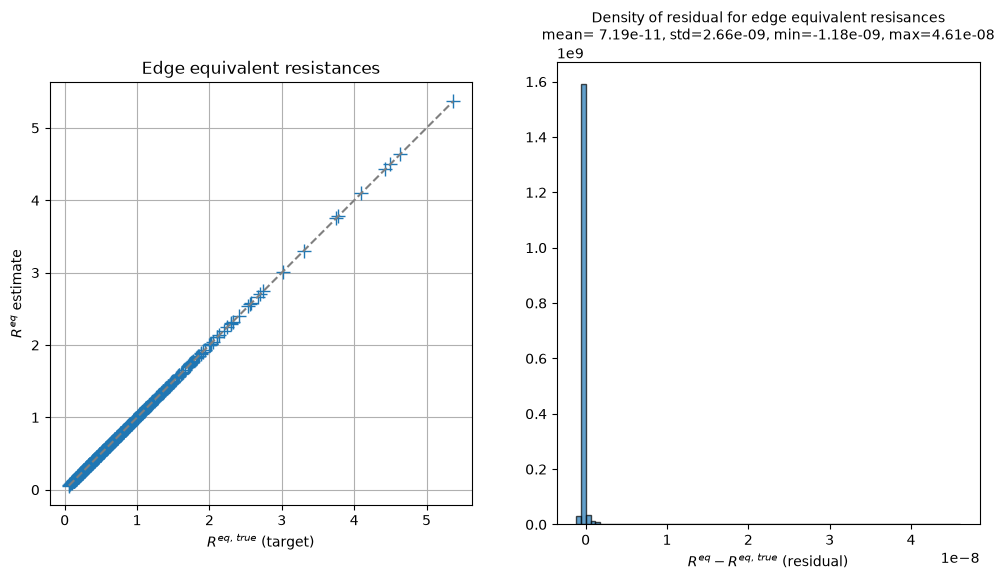

In [26]:
Req_estimate_arr = np.asarray([Req_estimate[e] for e in g.edges()])
# Req_true_arr = np.asarray([Req_true[e] for e in g.edges()]) # already defined above
# Req_residual_arr = Req_estimate_arr - Req_true_arr # already defined above

x0 = min(np.min(Req_true_arr), np.min(Req_estimate_arr))
x1 = max(np.max(Req_true_arr), np.max(Req_estimate_arr))
Req_col = 'tab:blue'

plt.subplots(1, 2, figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(Req_true_arr, Req_estimate_arr, ls='', marker='+', markersize=10, color=Req_col)
plt.plot([x0, x1], [x0, x1], ls='dashed', color='gray')
plt.xlabel(r'$R^{eq,\, true}$ (target)')
plt.ylabel(r'$R^{eq}$ estimate')
plt.gca().set_aspect('equal', adjustable='box')
plt.grid()
plt.title('Edge equivalent resistances')

plt.subplot(1, 2, 2)
plt.hist(Req_residual_arr, density=True, bins=80, color=Req_col, edgecolor='black', alpha=0.7)
plt.xlabel(r'$R^{eq} - R^{eq,\, true}$ (residual)')
plt.title('Density of residual for edge equivalent resisances\n' + 
          f'mean= {np.mean(Req_residual_arr):.2e}, std={np.std(Req_residual_arr):.2e}, ' + 
          f'min={np.min(Req_residual_arr):.2e}, max={np.max(Req_residual_arr):.2e}',
          fontsize=10)

plt.show()

- Errors on edge conductances (in this case the truth is known)

In [27]:
# T residual (array)
T_residual_arr = np.asarray([g.edges[e]['T_estimate'] - g.edges[e]['T_true'] for e in g.edges()])

# T errors
T_err_MaxAE = np.max(np.abs(Req_residual_arr)) # Maximum Absolute Error
T_err_MAE = np.mean(np.abs(Req_residual_arr)) # Mean Absolute Error
T_err_SAE = np.sum(np.abs(Req_residual_arr)) # Sum of Absolute Error
T_err_MSE = np.mean(Req_residual_arr**2) # Mean Square Error
T_err_RMSE = np.sqrt(np.mean(Req_residual_arr**2)) # Root Mean Square Error
T_err_SSE = np.sum(Req_residual_arr**2) # Sum of Square Error

print(f'T error (MaxAE) : {T_err_MaxAE:4e}')
print(f'T error (MAE)   : {T_err_MAE:4e}')
print(f'T error (SAE)   : {T_err_SAE:4e}')
print(f'T error (MSE)   : {T_err_MSE:4e}')
print(f'T error (RMSE)  : {T_err_RMSE:4e}')
print(f'T error (SSE)   : {T_err_SSE:4e}')

T error (MaxAE) : 4.606754e-08
T error (MAE)   : 3.970479e-10
T error (SAE)   : 2.529195e-07
T error (MSE)   : 7.080738e-18
T error (RMSE)  : 2.660966e-09
T error (SSE)   : 4.510430e-15


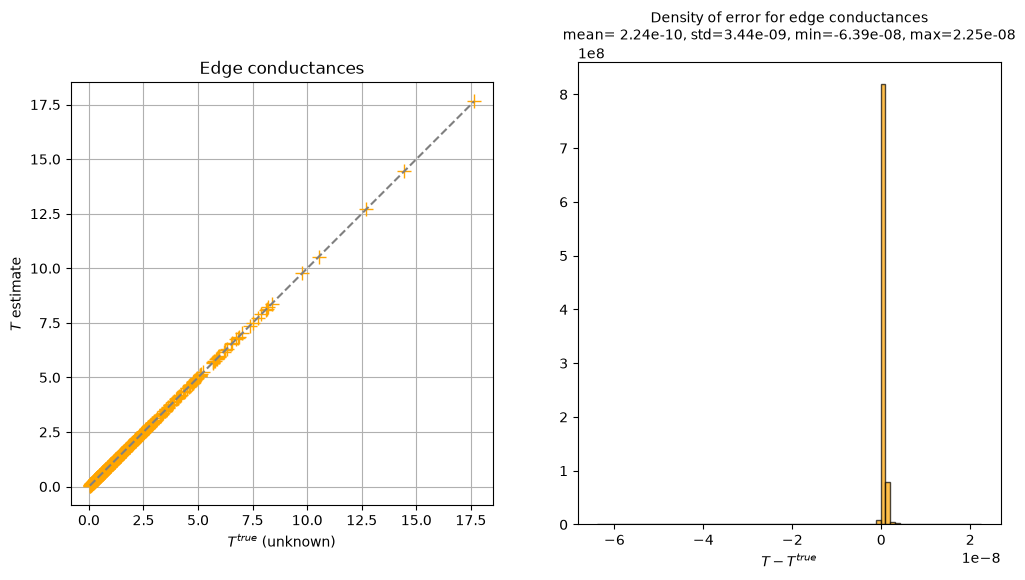

In [28]:
T_estimate_arr = np.asarray([g.edges[e]['T_estimate'] for e in g.edges()])
# T_estimate_arr = np.asarray(list(nx.get_edge_attributes(g, 'T_estimate').values())) # equiv.
# T_true_arr = np.asarray([T_true[e] for e in g.edges()]) # already defined above
# T_residual_arr = T_estimate_arr - T_true_arr # already defined above

x0 = min(np.min(T_true_arr), np.min(T_estimate_arr))
x1 = max(np.max(T_true_arr), np.max(T_estimate_arr))
T_col = 'orange'

plt.subplots(1, 2, figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(T_true_arr, T_estimate_arr, ls='', marker='+', markersize=10, color=T_col)
plt.plot([x0, x1], [x0, x1], ls='dashed', color='gray')
plt.xlabel(r'$T^{true}$ (unknown)')
plt.ylabel(r'$T$ estimate')
plt.gca().set_aspect('equal', adjustable='box')
plt.grid()
plt.title('Edge conductances')

plt.subplot(1, 2, 2)
plt.hist(T_residual_arr, density=True, bins=80, color=T_col, edgecolor='black', alpha=0.7)
plt.xlabel(r'$T - T^{true}$')
plt.title('Density of error for edge conductances\n' + 
          f'mean= {np.mean(T_residual_arr):.2e}, std={np.std(T_residual_arr):.2e}, ' + 
          f'min={np.min(T_residual_arr):.2e}, max={np.max(T_residual_arr):.2e}',
          fontsize=10)

plt.show()

### Inversion by optimisation - tracking successive estimates
The function `kn.tools.invert_Req` returns (optionally)
- `Req_estimate_dict` : the dictionary of the (final) edge equivalent resistances (corresponding to the (final) edge conductance estimates)
- `Req_err` : the error between the (final) edge equivalent resistance estimates and the target ones (type of error given by `Req_err_type`)
- `nit` : the number of iteration(s) done (in Gaussian-Newton algorithm), or the number of updates of the edge conductance estimates
- `Req_estimate_arr_list` : the list of arrays of edge equivalent resistance estimates, at each iteration: `Req_estimate_arr_list[i][j]` is the value at the `i`-th iteration for the `j`-th edge; list of length `nit + 1`
- `Req_err_list`, the list of errors between the edge equivalent resistance estimates and the target ones, at each iteration: `Req_err_list[i]` is the value for the `i`-th iteration; list of length `nit + 1`
- `return_T_estimate_arr_list=True`, the list of arrays of edge conductance estimates, at each iteration: `T_estimate_arr_list[i][j]` is the value at the `i`-th iteration for the `j`-th edge; list of length `nit + 1`

Note that
- the iteration `i=0` corresponds to initial (starting) values
- the edge `j` refers to the `j`-th edge returned by `g.edges()` (index starting from 0)


In [29]:
t1 = time.time()

# # Type of error (for stop criterion of Gauss-Newton algorithm)
# Req_err_type = 'MaxAE' # Maximum Absolute Error
# Req_err_type = 'MAE'   # Mean Absolute Error
# Req_err_type = 'SAE'   # Sum of Absolute Error
# Req_err_type = 'MSE'   # Mean Square Error
# Req_err_type = 'RMSE'  # Root Mean Square Error
# Req_err_type = 'SSE'   # Sum of Square Error

Req_err_type = 'SSE'   # Sum of Square Error

Req_estimate, Req_err, nit, Req_estimate_arr_list, Req_err_list, T_estimate_arr_list = kn.tools.invert_Req(
        g,
        Req_true,                     # dictionary of target (true) equivalent resistance on edges
        T_estimate_attr='T_estimate', # edge attribute name to store the conductance estimates
        T_estimate_start_dict=None,
        k=None,
        nit_max=100,
        tol=1.e-10,
        tol_step=1.e-10,
        T_clip_min=1.e-20,
        rescale_T=True,
        Req_err_type=Req_err_type,
        return_Req_estimate_dict=True,
        return_Req_err=True,
        return_nit=True,
        return_Req_estimate_arr_list=True,
        return_Req_err_list=True,
        return_T_estimate_arr_list=True,
        verbose=1)

t2 = time.time()
print(f'Number of iteration(s) (update of the estimates) : {nit}')
print(f'Final Req error ({Req_err_type}) = {Req_err:4e}')
print(f'Elapsed time: {t2-t1:.2f} sec')


Iteration   0 : Req error (SSE) = 2.610160e+01
Iteration   1 : Req error (SSE) = 7.141636e+00
Iteration   2 : Req error (SSE) = 2.060047e-01
Iteration   3 : Req error (SSE) = 1.092759e-03
Iteration   4 : Req error (SSE) = 1.233687e-07
Iteration   5 : Req error (SSE) = 4.510430e-15
Iteration   5 : convergence OK (Req error less than 1e-10)
Number of iteration(s) (update of the estimates) : 5
Final Req error (SSE) = 4.510430e-15
Elapsed time: 1.62 sec


In [30]:
Req_estimate_arr = np.asarray([Req_estimate[e] for e in g.edges()])
np.all(Req_estimate_arr == Req_estimate_arr_list[-1]) # Should be True

np.True_

In [31]:
T_estimate_arr = np.asarray([g.edges[e]['T_estimate'] for e in g.edges()])
# T_estimate_arr = np.asarray(list(nx.get_edge_attributes(g, 'T_estimate').values())) # equiv.
np.all(T_estimate_arr == T_estimate_arr_list[-1]) # Should be True

np.True_

In [32]:
Req_err == Req_err_list[-1] # Should be True

np.True_

- Show convergence (on edge equivalent resistances)

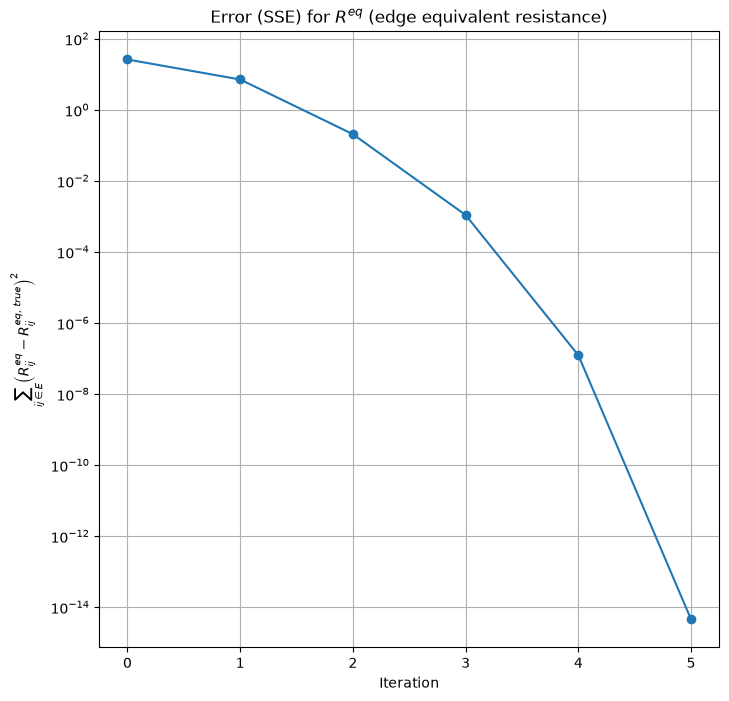

In [33]:
Req_col = 'tab:blue'
if Req_err_type == 'MaxAE':
    Req_err_str = r'$\max_{ij \in E} \left\vert R^{eq}_{ij} - R^{eq,\, true}_{ij}\right\vert$'
elif Req_err_type == 'MAE':
    Req_err_str = r'$\frac{1}{\vert E\vert}\sum_{ij \in E} \left\vert R^{eq}_{ij} - R^{eq,\, true}_{ij}\right\vert$'
elif Req_err_type == 'MSE':
    Req_err_str = r'$\frac{1}{\vert E\vert}\sum_{ij \in E} \left(R^{eq}_{ij} - R^{eq,\, true}_{ij}\right)^2$'
elif Req_err_type == 'RMSE':
    Req_err_str = r'$\left(\frac{1}{\vert E\vert}\sum_{ij \in E} \right(R^{eq}_{ij} - R^{eq,\, true}_{ij}\right)^2\right)^{1/2}$'
elif Req_err_type == 'SAE':
    Req_err_str = r'$\sum_{ij \in E} \left\vert R^{eq}_{ij} - R^{eq,\, true}_{ij}\right\vert$'
elif Req_err_type == 'SSE':
    Req_err_str = r'$\sum_{ij \in E} \left(R^{eq}_{ij} - R^{eq,\, true}_{ij}\right)^2$'

plt.figure(figsize=(8, 8))
plt.plot(Req_err_list, ls='solid', marker='o', color=Req_col)
plt.xlabel('Iteration')
plt.ylabel(Req_err_str)
plt.yscale('log')
plt.grid()
plt.title(f'Error ({Req_err_type}) ' + r'for $R^{eq}$ (edge equivalent resistance)')
plt.show()


- Recompute the errors of different types at each iteration (for edge equivalent resistances)

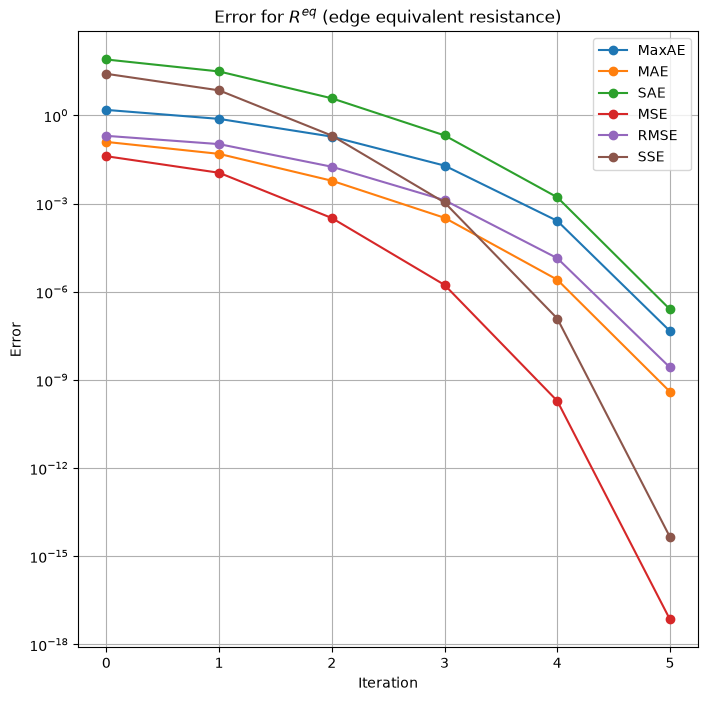

In [34]:
# List of Req residual (array)
# Req_true_arr = np.asarray([Req_true[e] for e in g.edges()]) # already defined above
Req_residual_arr_list = [Req_estimate_arr - Req_true_arr for Req_estimate_arr in Req_estimate_arr_list]

# List of Req errors
Req_err_MaxAE_list = [np.max(np.abs(Req_residual_arr))      for Req_residual_arr in Req_residual_arr_list] # Maximum Absolute Error
Req_err_MAE_list   = [np.mean(np.abs(Req_residual_arr))     for Req_residual_arr in Req_residual_arr_list] # Mean Absolute Error
Req_err_SAE_list   = [np.sum(np.abs(Req_residual_arr))      for Req_residual_arr in Req_residual_arr_list] # Sum of Absolute Error
Req_err_MSE_list   = [np.mean(Req_residual_arr**2)          for Req_residual_arr in Req_residual_arr_list] # Mean Square Error
Req_err_RMSE_list  = [np.sqrt(np.mean(Req_residual_arr**2)) for Req_residual_arr in Req_residual_arr_list] # Root Mean Square Error
Req_err_SSE_list   = [np.sum(Req_residual_arr**2)           for Req_residual_arr in Req_residual_arr_list] # Sum of Square Error

plt.figure(figsize=(8, 8))
for y, lab in zip(
        [Req_err_MaxAE_list, Req_err_MAE_list, Req_err_SAE_list, Req_err_MSE_list, Req_err_RMSE_list, Req_err_SSE_list],
        ['MaxAE'           , 'MAE'           , 'SAE'           , 'MSE'           , 'RMSE'           , 'SSE']):
    plt.plot(y, ls='solid', marker='o', label=lab)
    plt.xlabel('Iteration')
    plt.ylabel('Error')

plt.legend()
plt.yscale('log')
plt.grid()
plt.title(r'Error for $R^{eq}$ (edge equivalent resistance)')
plt.show()

- Show convergence (on edge conductances, known in this case), for different type of errors

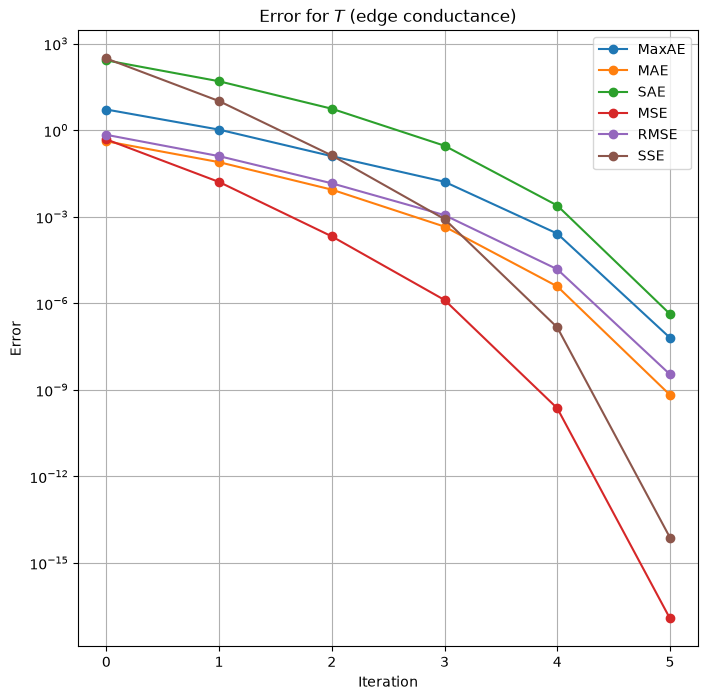

In [35]:
# List of Req residual (array)
# T_true_arr = np.asarray([T_true[e] for e in g.edges()]) # already defined above
T_residual_arr_list = [T_estimate_arr - T_true_arr for T_estimate_arr in T_estimate_arr_list]

# List of T errors
T_err_MaxAE_list = [np.max(np.abs(T_residual_arr))      for T_residual_arr in T_residual_arr_list] # Maximum Absolute Error
T_err_MAE_list   = [np.mean(np.abs(T_residual_arr))     for T_residual_arr in T_residual_arr_list] # Mean Absolute Error
T_err_SAE_list   = [np.sum(np.abs(T_residual_arr))      for T_residual_arr in T_residual_arr_list] # Sum of Absolute Error
T_err_MSE_list   = [np.mean(T_residual_arr**2)          for T_residual_arr in T_residual_arr_list] # Mean Square Error
T_err_RMSE_list  = [np.sqrt(np.mean(T_residual_arr**2)) for T_residual_arr in T_residual_arr_list] # Root Mean Square Error
T_err_SSE_list   = [np.sum(T_residual_arr**2)           for T_residual_arr in T_residual_arr_list] # Sum of Square Error

plt.figure(figsize=(8, 8))
for y, lab in zip(
        [T_err_MaxAE_list, T_err_MAE_list, T_err_SAE_list, T_err_MSE_list, T_err_RMSE_list, T_err_SSE_list],
        ['MaxAE'         , 'MAE'         , 'SAE'         , 'MSE'         , 'RMSE'         , 'SSE']):
    plt.plot(y, ls='solid', marker='o', label=lab)
    plt.xlabel('Iteration')
    plt.ylabel('Error')

plt.legend()
plt.yscale('log')
plt.grid()
plt.title(r'Error for $T$ (edge conductance)')
plt.show()